<a href="https://colab.research.google.com/github/ehuangasu/MAT422/blob/main/MAT422_Section_3_2_Limits_Derivatives_Taylor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ehuangasu/MAT422/blob/main/MAT422_Section_3_2_Limits_Derivatives_Taylor.ipynb)

# MAT 422 - Section 3.2: Limits, Derivatives, and Taylor's Theorem

**Topics:** Limits and continuity, Derivatives, Taylor's theorem

> Student note: This Colab badge is required for submission. Create or edit the notebook in Google Colab, then save it directly to GitHub so the badge/icon remains available for grading and reruns.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)


## Limits and continuity

A function f has a limit L at x=a (lim x->a f(x) = L) if f(x) gets closer to L if x is closer to a. The exact value of f(a) is not important here and may not exist.

A limit may be approached from two sides: positive and negative. The limit exists only if both one-sided limits exist and are equal.

A function is continuous at a if f(a) is defined, lim x->a f(x) exists, and lim x->a f(x) = f(a).

h values: [1.    0.5   0.1   0.01  0.001]
sin(h)/h: [0.841471 0.958851 0.998334 0.999983 1.      ]
These values approach 1 as h approaches 0.


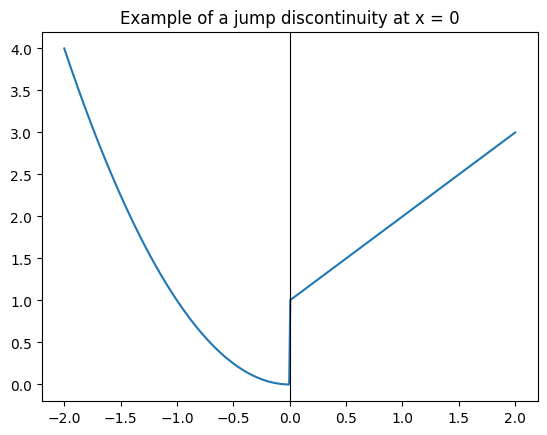

In [2]:
h = np.array([1, 0.5, 0.1, 0.01, 0.001])
values = np.sin(h) / h
print("h values:", h)
print("sin(h)/h:", values)
print("These values approach 1 as h approaches 0.")

x = np.linspace(-2, 2, 400)
y = np.where(x < 0, x**2, x + 1)
plt.plot(x, y)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Example of a jump discontinuity at x = 0")
plt.show()


The limit here does not exist because the limit from the left (0) and the limit from the right (1) are different. So it is also not continuous.

f(0 - h), from the left : [0.25     0.0625   0.015625 0.003906 0.000977 0.000244]
f(0 + h), from the right: [1.5      1.25     1.125    1.0625   1.03125  1.015625]


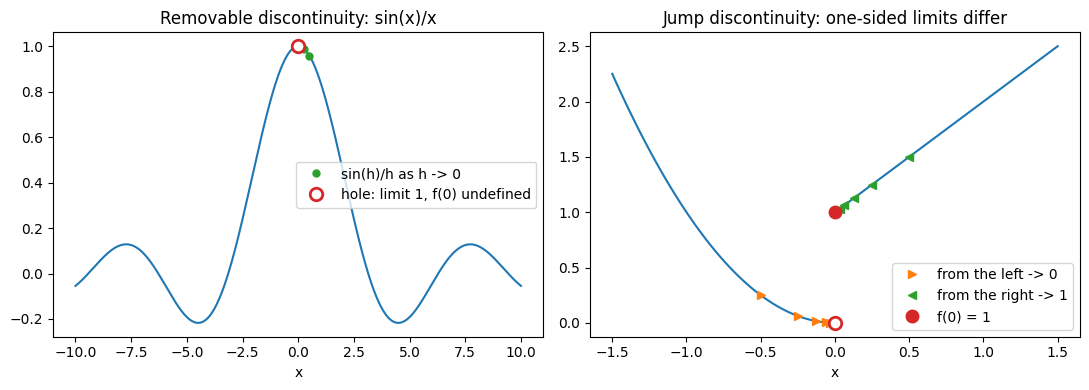

In [6]:
def jump(x):
    return np.where(x < 0, x**2, x + 1)        # same function as the starter plot

steps = 0.5 ** np.arange(1, 7)                 # 0.5, 0.25, ..., 0.015625
print("f(0 - h), from the left :", jump(-steps))
print("f(0 + h), from the right:", jump(steps))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# (a) sin(x)/x: a removable "hole" at x = 0
xs = np.linspace(-10, 10, 1000)                # even count, so x = 0 is never sampled
ax[0].plot(xs, np.sin(xs) / xs)
ax[0].plot(steps, np.sin(steps) / steps, "o", color="C2", ms=5, label="sin(h)/h as h -> 0")
ax[0].plot(0, 1, "o", mfc="white", mec="C3", ms=9, mew=2, label="hole: limit 1, f(0) undefined")
ax[0].set(title="Removable discontinuity: sin(x)/x", xlabel="x")
ax[0].legend()

# (b) jump: the left and right limits disagree
left, right = np.linspace(-1.5, 0, 100), np.linspace(0, 1.5, 100)
ax[1].plot(left, left**2, "C0")
ax[1].plot(right, right + 1, "C0")
ax[1].plot(-steps, jump(-steps), ">", color="C1", label="from the left -> 0")
ax[1].plot(steps, jump(steps), "<", color="C2", label="from the right -> 1")
ax[1].plot(0, 0, "o", mfc="white", mec="C3", ms=9, mew=2)
ax[1].plot(0, 1, "o", color="C3", ms=9, label="f(0) = 1")
ax[1].set(title="Jump discontinuity: one-sided limits differ", xlabel="x")
ax[1].legend()
plt.tight_layout()
plt.show()

There are two main types of discontinuity: a hole and a jump. The hole discontinuity limit does exist, but the jump does not.

(There are other stranger ones but those are not important)

## Derivatives

The derivative is the slope of a graph at a single point. rise/run is undefined here because run=0, so we use a limit instead: lim h->0 (f(a+h)-f(a))/h is basically the limit of rise/run at f(a).


The code below uses (f(a+h)-f(a-h))/2h which is similar:

In [3]:
def f(x):
    return x**3 - 2*x + 1

point = 1.5
steps = np.array([1e-1, 1e-2, 1e-3, 1e-4])
numeric_derivatives = (f(point + steps) - f(point - steps)) / (2 * steps)
exact_derivative = 3 * point**2 - 2

print("numeric derivative estimates:", numeric_derivatives)
print("exact derivative:", exact_derivative)
print("errors:", np.abs(numeric_derivatives - exact_derivative))


numeric derivative estimates: [4.76     4.7501   4.750001 4.75    ]
exact derivative: 4.75
errors: [0.01     0.0001   0.000001 0.      ]


The estimate of the derivate gets closer and closer to the exact.

We can see the secant lines getting closer to the real one:

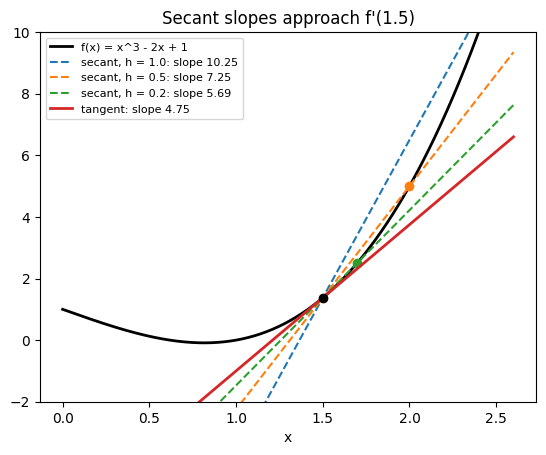

In [10]:
a = point
xs = np.linspace(0, 2.6, 300)
plt.plot(xs, f(xs), "k", lw=2, label="f(x) = x^3 - 2x + 1")

# secant lines turn into the tangent line as h shrinks
for h, color in zip([1.0, 0.5, 0.2], ["C0", "C1", "C2"]):
    slope = (f(a + h) - f(a)) / h
    plt.plot(xs, f(a) + slope * (xs - a), "--", color=color, label=f"secant, h = {h}: slope {slope:.2f}")
    plt.plot(a + h, f(a + h), "o", color=color)
plt.plot(xs, f(a) + exact_derivative * (xs - a), color="C3", lw=2, label=f"tangent: slope {exact_derivative}")
plt.plot(a, f(a), "ko")
plt.ylim(-2, 10)
plt.xlabel("x")
plt.title("Secant slopes approach f'(1.5)")
plt.legend(fontsize=8)
plt.show()

## Taylor's theorem

Near a, a function can be approximated by a polynomial using its derivatives:

f(a)+f'(a)(x-a)+f''(a)/2 * (x-a)^2... f^n(a)/n! * (x-a)^n

The term f'(a)(x-a) is the secant line.

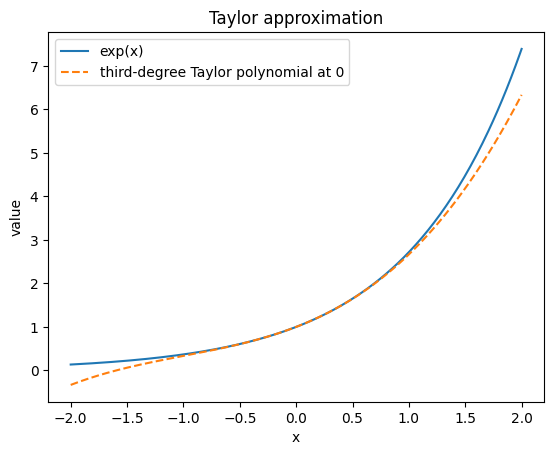

Max error on [-1, 1] = 0.050889128724262545


In [4]:
x = np.linspace(-2, 2, 300)
taylor_exp = 1 + x + x**2 / 2 + x**3 / 6

plt.plot(x, np.exp(x), label="exp(x)")
plt.plot(x, taylor_exp, "--", label="third-degree Taylor polynomial at 0")
plt.xlabel("x")
plt.ylabel("value")
plt.title("Taylor approximation")
plt.legend()
plt.show()

print("Max error on [-1, 1] =", np.max(np.abs(np.exp(x[np.abs(x) <= 1]) - taylor_exp[np.abs(x) <= 1])))


We can see the polynomial being close to exp(x). We also do a few approximations for sin(x):

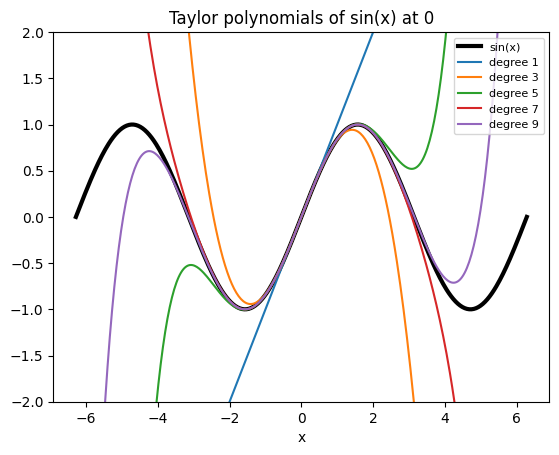

In [13]:
from math import factorial

# higher-degree Taylor polynomials of sin(x) hug the curve over a wider range
xs = np.linspace(-2 * np.pi, 2 * np.pi, 400)
plt.plot(xs, np.sin(xs), "k", lw=3, label="sin(x)")
for n in [1, 3, 5, 7, 9]:
    p_n = sum((-1)**k * xs**(2*k + 1) / factorial(2*k + 1) for k in range((n + 1) // 2))
    plt.plot(xs, p_n, label=f"degree {n}")
plt.ylim(-2, 2)
plt.xlabel("x")
plt.title("Taylor polynomials of sin(x) at 0")
plt.legend(fontsize=8)
plt.show()

With higher degree, the polynomial becomes accurate for a wider range of x.

## Reflection and Submission Checklist

- I explained each concept in words before or after the code.
- I verified important claims numerically or visually.
- I changed or extended at least one example so the notebook reflects my own work.
- I ran the notebook from top to bottom without errors.
- I saved the notebook from Google Colab directly to GitHub, following the course instructions.
